In [209]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             confusion_matrix, roc_curve, auc)

In [210]:
columns = ['Sex', 'Length', 'Diameter',
           'Height', 'Whole weight', 'Shucked weight',
           'Viscera weight', 'Shell weight', 'Rings']
df = pd.read_csv('abalone.data', names=columns, header=None)

In [211]:
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [212]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 293.8 KB


In [213]:
df.shape

(4177, 9)

In [214]:
# Проверяем дубликаты
df.duplicated().sum()

np.int64(0)

In [215]:
# Проверяем распределение Rings
df['Rings'].value_counts().sort_index()

Rings
1       1
2       1
3      15
4      57
5     115
6     259
7     391
8     568
9     689
10    634
11    487
12    267
13    203
14    126
15    103
16     67
17     58
18     42
19     32
20     26
21     14
22      6
23      9
24      2
25      1
26      1
27      2
29      1
Name: count, dtype: int64

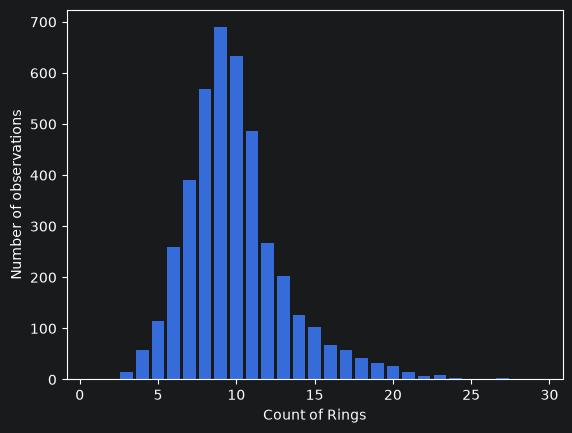

In [216]:
# Строим диаграмму на основе количества колец и наблюдениями
distribution_rings = df['Rings'].value_counts().sort_index()
plt.bar(distribution_rings.index, distribution_rings.values)
plt.xlabel('Count of Rings')
plt.ylabel('Number of observations')
plt.show()

Чаще всего встречаются моллюски с 8–11 кольцами; максимум приходится на 9 колец. Распределение имеет длинный правый хвост: наблюдения с большим количеством колец редки.

In [217]:
# Посчитаем кол-во наблюдений диапазона колец (<= 7, 8-11, >= 12)
# Наблюдаю сильный дисбаланс, если модель выберет среднюю групу, получит около 56,9% accuracy
print(f'{(df['Rings'] <= 7).sum()}, {(df['Rings'].between(8, 11)).sum()}, {(df['Rings'] >= 12).sum()}')

839, 2378, 960


In [218]:
# Классифицируем по трем диапазонам колец, Rings_group - цель
bins = [0, 7, 11, 100]
labels = ['low', 'medium', 'high']
rings_group = pd.cut(df['Rings'], bins=bins, labels=labels, right=True)
df['Rings_group'] = rings_group
df['Rings_group']

0         high
1          low
2       medium
3       medium
4          low
         ...  
4172    medium
4173    medium
4174    medium
4175    medium
4176      high
Name: Rings_group, Length: 4177, dtype: category
Categories (3, str): ['low' < 'medium' < 'high']

In [219]:
df.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [220]:
# Находим строки с нулевой высотой или высотой больше длины
df[(df['Height'] <= 0) | (df['Height'] > df['Length'])]

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings,Rings_group
1257,I,0.430,0.340,0.00,0.428,0.2065,0.0860,0.1150,8,medium
2051,F,0.455,0.355,1.13,0.594,0.3320,0.1160,0.1335,8,medium
3996,I,0.315,0.230,0.00,0.134,0.0575,0.0285,0.3505,6,low


In [221]:
# По принятому правилу заменяем подозрительные значения Height на пропуски
invalid_height = (df['Height'] <= 0) | (df['Height'] > df['Length'])
df.loc[invalid_height, 'Height'] = float('nan')
df['Height'].isna().sum()

np.int64(3)

In [222]:
# Проверяем, есть ли в Whole weight нули.
(df['Whole weight'] == 0).sum()

np.int64(0)

In [223]:
# Создаём признак: отношение массы мяса к общей массе моллюска.
meat_fraction = df['Shucked weight'] / df['Whole weight']
df['Meat_fraction'] = meat_fraction
df['Meat_fraction'].describe()

count    4177.000000
mean        0.432414
std         0.105765
min         0.175258
25%         0.395100
50%         0.430592
75%         0.466175
max         4.691943
Name: Meat_fraction, dtype: float64

In [224]:
# Заменяем доли больше 1 на пропуски: масса мяса не должна превышать общую массу.
# Проверяем количество пропусков в созданной фичей.
df.loc[(df['Meat_fraction'] > 1), 'Meat_fraction'] = float('nan')
df['Meat_fraction'].isna().sum()

np.int64(4)

In [225]:
# Создаём признак: отношение диаметра раковины к её длине.
diameter_length_ratio = df['Diameter'] / df['Length']
df['Diameter_length_ratio'] = diameter_length_ratio
df['Diameter_length_ratio'].describe()

count    4177.000000
mean        0.775714
std         0.038367
min         0.428571
25%         0.756522
50%         0.776119
75%         0.795082
max         2.027027
Name: Diameter_length_ratio, dtype: float64

In [226]:
# Считаем отношение диаметра к длине больше 1 подозрительным и заменяем на NaN.
# Проверяем количество пропусков в созданном признаке.
df.loc[(df['Diameter_length_ratio'] > 1), 'Diameter_length_ratio'] = float('nan')
df['Diameter_length_ratio'].isna().sum()

np.int64(1)

In [227]:
# Выделяем признаки и целевую переменную Rings_group.
# Исключаем Rings из признаков, поскольку по нему сформированы классы.
# сохраняя примерно одинаковые доли классов с помощью stratify.
x = df.drop(columns=['Rings_group', 'Rings'])
y = df['Rings_group']

# 60% train дата, 20% valid дата, 20% test дата
x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

In [228]:
# Выбираем числовые фичи и вычисляем их медианы только на train.
# Заполняем пропуски во всех выборках медианами тренировочной части.
numeric_cols = x_train.select_dtypes(include='number').columns
train_medians = x_train[numeric_cols].median()

x_train_filled = x_train.fillna(train_medians)
x_val_filled = x_val.fillna(train_medians)
x_test_filled = x_test.fillna(train_medians)

In [229]:
# Масштабируем фичи
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train_filled[numeric_cols])
x_val_scaled = scaler.transform(x_val_filled[numeric_cols])
x_test_scaled = scaler.transform(x_test_filled[numeric_cols])

In [230]:
# Закодируем Sex в отдельные бинарные столбцы.
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
sex_train_encoded = encoder.fit_transform(x_train_filled[['Sex']])
sex_val_encoded = encoder.transform(x_val_filled[['Sex']])
sex_test_encoded = encoder.transform(x_test_filled[['Sex']])

In [231]:
# Объединяем масштабированные числовые фичи и закодированный Sex.
# Получаем по 12 входных признаков для каждой выборки.
x_train_ready = np.hstack((x_train_scaled, sex_train_encoded))
x_val_ready = np.hstack((x_val_scaled, sex_val_encoded))
x_test_ready = np.hstack((x_test_scaled, sex_test_encoded))

In [232]:
# Обучаем логистическую регрессию с параметрами по умолчанию.
# Оцениваем её на validation по accuracy и F1 macro.
# Сохраняем результаты для сравнения с другими настройками.
model = LogisticRegression()

model.fit(x_train_ready, y_train)
y_val_pred = model.predict(x_val_ready)

# Accuracy
baseline_accuracy = accuracy_score(y_val, y_val_pred)

# F1
baseline_f1 = f1_score(y_val, y_val_pred, average='macro')

print(f'{baseline_accuracy}, {baseline_f1}')

0.7392344497607656, 0.7035384866405764


In [233]:
# Выводим precision, recall, F1 и число наблюдений для каждого класса.
# Оцениваем базовую модель на валидационной выборке.
class_report = classification_report(y_val, y_val_pred)
print(class_report)

              precision    recall  f1-score   support

        high       0.70      0.52      0.59       192
         low       0.81      0.66      0.73       168
      medium       0.73      0.86      0.79       476

    accuracy                           0.74       836
   macro avg       0.75      0.68      0.70       836
weighted avg       0.74      0.74      0.73       836



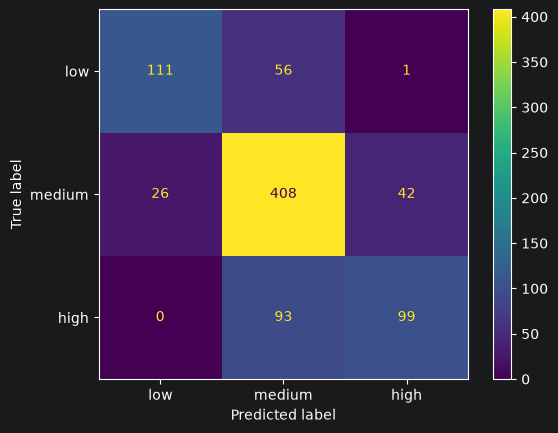

In [234]:
# Строим матрицу ошибок базовой модели на validation.
# Строки соответствуют истинным классам, столбцы - предсказанным.
labels=['low', 'medium', 'high']
cm = confusion_matrix(y_val, y_val_pred, labels=labels)
disp = ConfusionMatrixDisplay(cm, display_labels=labels)
disp.plot()
plt.show()

Матрица показывает результаты базовой модели на валидационной выборке. Строки соответствуют истинным классам, столбцы - предсказанным. На главной диагонали расположены правильные прогнозы: 111 для low, 408 для medium и 99 для high.

In [235]:
# Обучаем модель с весами, обратно пропорциональными частотам классов.
# Проверяем, улучшает ли class_weight='balanced' метрики на validation.
balanced_model = LogisticRegression(class_weight='balanced')

balanced_model.fit(x_train_ready, y_train)
balanced_val_pred = balanced_model.predict(x_val_ready)

# Accuracy Balanced
balanced_accuracy = accuracy_score(y_val, balanced_val_pred)

# F1 Balanced
balanced_f1 = f1_score(y_val, balanced_val_pred, average='macro')

print(f'{balanced_accuracy}, {balanced_f1}')

0.6830143540669856, 0.6860423234523955


In [236]:
# Перебираем значения C: чем меньше C, тем сильнее регуляризация.
# Для каждого варианта вычисляем F1 macro на validation.
# Сохраняем параметры и результаты в таблицу.
C_values = [0.01, 0.1, 1, 10, 100]
results = []
for C in C_values:
    logistic_model = LogisticRegression(C=C)

    logistic_model.fit(x_train_ready, y_train)

    logistic_val_pred = logistic_model.predict(x_val_ready)

    # F1
    logistic_f1 = f1_score(y_val, logistic_val_pred, average='macro')

    results.append({'C': C, 'f1_score': logistic_f1})

results_df = pd.DataFrame(results)
results_df

,C,f1_score
0,0.01,0.682304
1,0.10,0.706798
2,1.00,0.703538
3,10.00,0.703964
4,100.00,0.704412


In [237]:
# Выбираем C с максимальным F1 macro на validation.
# Обучаем отдельную модель с выбранным C на train.
# Проверяем её валидационные accuracy и F1 macro.
best_index = results_df['f1_score'].idxmax()
best_C = results_df.loc[best_index]['C']

best_model = LogisticRegression(C=best_C)

best_model.fit(x_train_ready, y_train)
best_val_pred = best_model.predict(x_val_ready)

# Accuracy best
best_accuracy = accuracy_score(y_val, best_val_pred)

# F1 best
best_f1 = f1_score(y_val, best_val_pred, average='macro')

print(f'{best_accuracy}, {best_f1}')

0.742822966507177, 0.7067977978549776


In [238]:
# Получаем вероятности классов и прогнозы выбранной модели на test.
# Вычисляем итоговые accuracy и F1 macro.
# Проверяем размер массива вероятностей и порядок классов в его столбцах.
test_proba = best_model.predict_proba(x_test_ready)

test_pred = best_model.predict(x_test_ready)

# Accuracy test
test_accuracy = accuracy_score(y_test, test_pred)

# F1
test_f1 = f1_score(y_test, test_pred, average='macro')

print(f'{test_accuracy}, {test_f1}, {test_proba.shape}, {best_model.classes_}')

0.7523923444976076, 0.7120257590439509, (836, 3), ['high' 'low' 'medium']


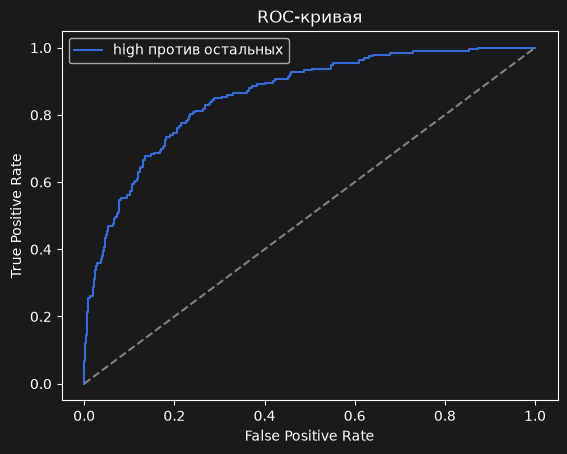

In [239]:
# Строим ROC-кривую для класса high против остальных на тестовой выборке.
# Используем вероятности high из первого столбца test_proba.
# Добавляем диагональ как ориентир случайного ранжирования.
y_test_high = (y_test == 'high')
fpr, tpr, thresholds = roc_curve(y_test_high, test_proba[:, 0])

plt.plot(fpr, tpr, label='high против остальных')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend()
plt.show()

График показывает, как меняются доля найденных объектов high и доля ложных срабатываний при изменении порога вероятности. Оценка выполнена на тестовой выборке по схеме «high против остальных».

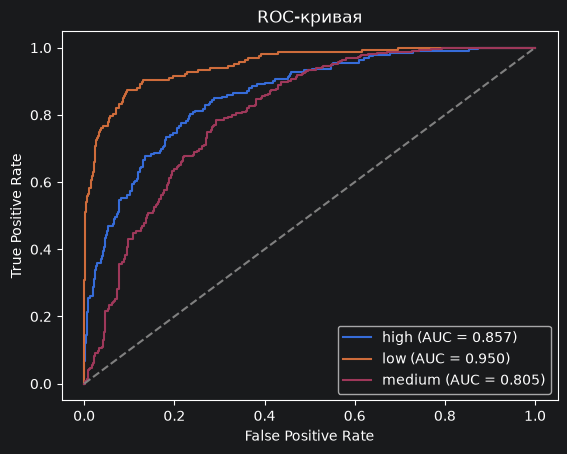

In [240]:
# Строим тестовые ROC-кривые по схеме «каждый класс против остальных».
# Берём столбцы вероятностей в порядке best_model.classes_.
# Вычисляем AUC для каждого класса и добавляем значения в легенду.
for i, class_name in enumerate(best_model.classes_):
    y_test_binary = (y_test == class_name)
    fpr, tpr, thresholds = roc_curve(y_test_binary, test_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{class_name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend()
plt.show()

Для каждого класса построена отдельная ROC-кривая по схеме «один против остальных» на тестовой выборке.


Итоговое заключение

После подготовки данных и подбора параметров выбрана логистическая регрессия с C = 0,1. На тесте получены accuracy = 0,752 и F1 macro = 0,712. Настройка дала небольшое улучшение относительно базовой модели. По ROC-AUC лучше всего отделяется класс low - 0,950.